# Task 5: Netflix Trend Forecasting Model
**Auspify Technologies – Machine Learning Internship**

Goal: forecast future Netflix content release trends from historical data (time series forecasting).

**Plan**
1. Prepare time-based features

2. Analyze historical release patterns

3. Build forecasting models

4. Generate future predictions

5. Evaluate forecasting accuracy

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

sns.set_theme(style="whitegrid")
RS = 42
df = pd.read_csv("Dataset.csv").drop_duplicates(subset="title")
df["date_added"] = pd.to_datetime(df["date_added"], format="%m/%d/%Y")
print(df.shape)
print("First date added:", df["date_added"].min().date(), "| Last date added:", df["date_added"].max().date())

(8787, 10)
First date added: 2008-01-01 | Last date added: 2021-09-25


## 1. Prepare time-based features

The dataset has two time columns:
- `release_year`: when the title was **produced** (goes back to 1925, so it is not a Netflix trend).
- `date_added`: when the title was **added to Netflix**. This is the only column with monthly resolution, so it is what we forecast: the number of titles added to Netflix each month.

We count titles per month and fill empty months with 0.

In [2]:
monthly = df.groupby(df["date_added"].dt.to_period("M")).size()
monthly.index = monthly.index.to_timestamp()
monthly = monthly.reindex(pd.date_range(monthly.index.min(), monthly.index.max(), freq="MS"), fill_value=0)

yearly = df["date_added"].dt.year.value_counts().sort_index()
print(yearly.to_string())

date_added
2008       2
2009       2
2010       1
2011      13
2012       3
2013      11
2014      24
2015      82
2016     426
2017    1185
2018    1647
2019    2014
2020    1879
2021    1498


Two decisions come from this table:
- **Start in 2016.** Before 2016 there are only a few titles per year (the catalogue was almost empty in this data), which would distort the trend.

- **Drop September 2021.** The data stops on 25 September 2021, so that month is incomplete.


The series used for modelling therefore runs from **January 2016 to August 2021** (68 months).

Months: 68 | from 2016-01-01 to 2021-08-01


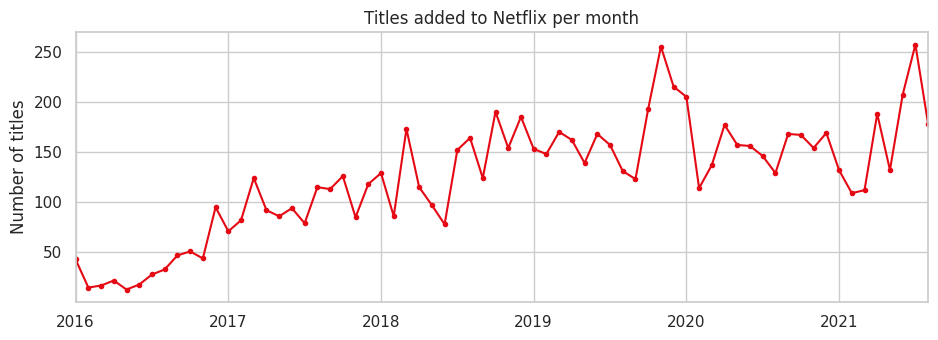

In [3]:
ts = monthly["2016-01-01":"2021-08-01"].astype(float)
ts.index.freq = "MS"
print("Months:", len(ts), "| from", ts.index[0].date(), "to", ts.index[-1].date())

ts.plot(figsize=(11, 3.5), color="#e50914", marker="o", ms=3)
plt.title("Titles added to Netflix per month"); plt.ylabel("Number of titles"); plt.show()

Time-based features for the machine learning models: calendar features (month encoded as sine/cosine so December is close to January), a trend index, **lags** (values 1, 2, 3 and 12 months ago) and **rolling means** of the previous 3 and 6 months. Lags and rolling means only use past values, so there is no leakage from the future.

In [4]:
def make_features(s):
    f = pd.DataFrame({"y": s})
    f["t"] = np.arange(len(f))
    f["month_sin"] = np.sin(2 * np.pi * f.index.month / 12)
    f["month_cos"] = np.cos(2 * np.pi * f.index.month / 12)
    for lag in (1, 2, 3, 12):
        f[f"lag_{lag}"] = f["y"].shift(lag)
    f["roll_mean_3"] = f["y"].shift(1).rolling(3).mean()
    f["roll_mean_6"] = f["y"].shift(1).rolling(6).mean()
    return f

features = make_features(ts)
features.dropna().head()

,y,t,month_sin,month_cos,lag_1,lag_2,lag_3,lag_12,roll_mean_3,roll_mean_6
2017-01-01,71.0,12,0.500000,8.660254e-01,95.0,44.0,51.0,43.0,63.333333,49.666667
2017-02-01,82.0,13,0.866025,5.000000e-01,71.0,95.0,44.0,15.0,70.000000,56.833333
2017-03-01,124.0,14,1.000000,6.123234e-17,82.0,71.0,95.0,17.0,82.666667,65.000000
2017-04-01,92.0,15,0.866025,-5.000000e-01,124.0,82.0,71.0,22.0,92.333333,77.833333
2017-05-01,86.0,16,0.500000,-8.660254e-01,92.0,124.0,82.0,13.0,99.333333,84.666667


## 2. Analyze historical release patterns

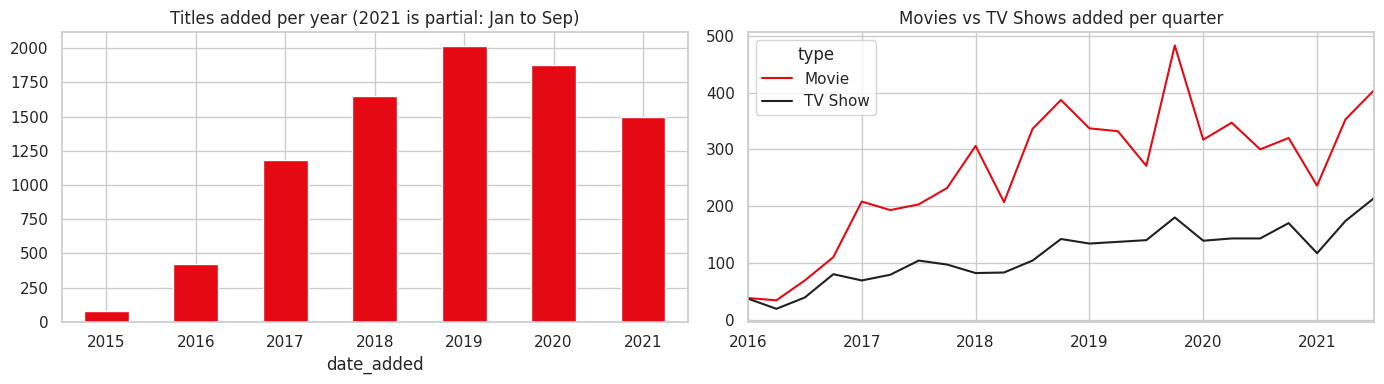

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
yearly.loc[2015:].plot.bar(ax=axes[0], color="#e50914", rot=0)
axes[0].set_title("Titles added per year (2021 is partial: Jan to Sep)")

mix = df[df["date_added"] >= "2016-01-01"].groupby([df["date_added"].dt.to_period("Q"), "type"]).size().unstack()
mix.index = mix.index.to_timestamp()
mix.plot(ax=axes[1], color=["#e50914", "#221f1f"])
axes[1].set_title("Movies vs TV Shows added per quarter"); axes[1].set_xlabel("")
plt.tight_layout(); plt.show()


### Interpretation: historical patterns

**Titles added per year (left):** Additions grew quickly from 2016 to 2019 (426 to about 2,014 titles), then levelled off. The 2021 bar looks lower only because it covers January to September. At roughly 165 titles a month, the pace is close to 2019 and 2020.

**Movies vs TV Shows per quarter (right):** Movies are added at about twice the rate of TV shows, and both follow the same shape: fast growth until 2017, then a bumpier plateau. The biggest spike is in late 2019 (close to 480 movies in one quarter), and the first quarter of each year is often weak.

The plateau explains why the forecast is flat, and the different behaviour of movies and TV shows suggests forecasting them separately in a future vers

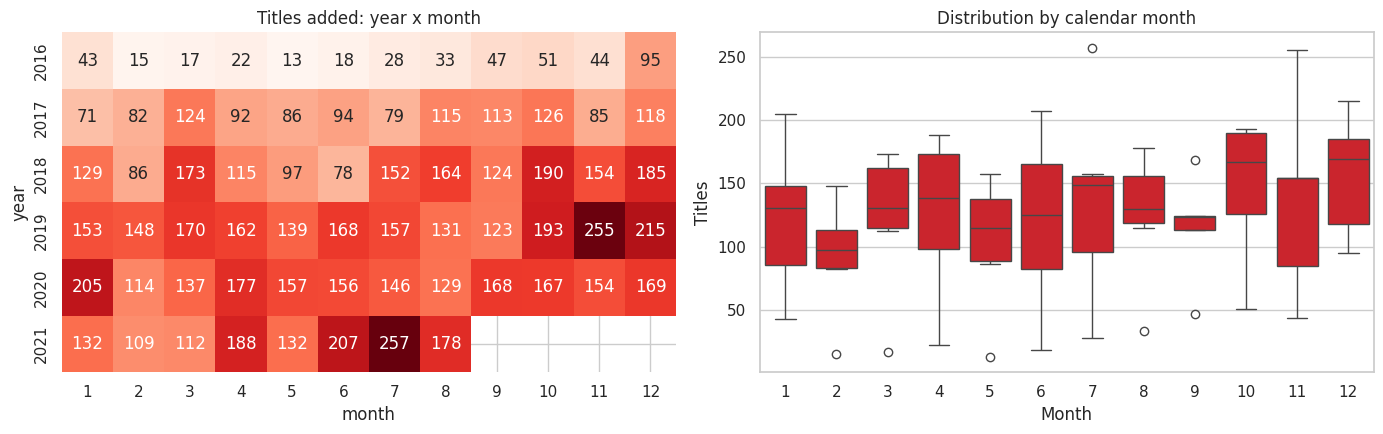

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
pivot = ts.to_frame("n").assign(year=ts.index.year, month=ts.index.month).pivot(index="year", columns="month", values="n")
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="Reds", cbar=False, ax=axes[0])
axes[0].set_title("Titles added: year x month")

sns.boxplot(x=ts.index.month, y=ts.values, color="#e50914", ax=axes[1])
axes[1].set_title("Distribution by calendar month"); axes[1].set_xlabel("Month"); axes[1].set_ylabel("Titles")
plt.tight_layout(); plt.show()


### Interpretation: seasonal patterns

**Heatmap (left):** Monthly additions climbed from just 13 to 95 titles in 2016 to roughly 110 to 255 by 2019 to 2021. The two biggest months are November 2019 (255) and July 2021 (257). February is usually one of the quietest months, though not in 2019, while October to December tend to be strong. September 2021 is blank because that month was incomplete, so I left it out.

**Boxplot (right):** February typically has the fewest additions (median around 97), while October and December have the most (medians around 165 to 170). The boxes overlap a lot and there are several outliers, so the yearly pattern is real but fairly weak, which fits the seasonality strength of 0.35. Some of the spread also comes from the 2016 growth years rather than from seasonality.


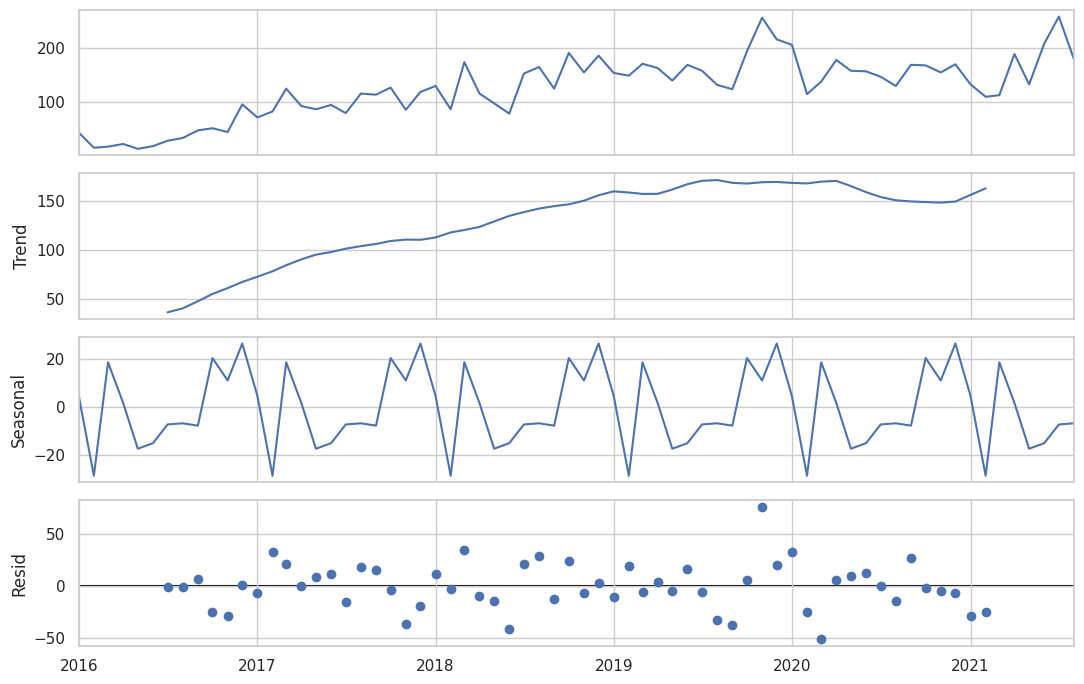

Strength of seasonality (0 = none, 1 = very strong): 0.35


In [7]:
dec = seasonal_decompose(ts, model="additive", period=12)
fig = dec.plot(); fig.set_size_inches(11, 7); plt.tight_layout(); plt.show()

seasonal_strength = max(0, 1 - dec.resid.var() / (dec.resid + dec.seasonal).var())
print(f"Strength of seasonality (0 = none, 1 = very strong): {seasonal_strength:.2f}")

### Interpretation: seasonal decomposition

**Trend:** The underlying level climbed steadily from about 40 titles a month in mid-2016 to roughly 170 by 2019. After that it stayed flat, slipped to about 150 in late 2020, and started to recover in early 2021. The trend line is shorter than the data because the method needs six months on each side to calculate it.

**Seasonal:** The same pattern repeats every year and swings about 25 titles above or below the trend. December is the strongest month (around +27) and February the weakest (around -29).

**Residuals:** What is left over is mostly within 40 titles of zero, which means trend and season explain most of the movement. The exceptions are November 2019 (about +75) and early 2020 (about -50), unusual months that neither component can explain.


ADF test p-value, original series : 0.045  (below 0.05 = stationary; the first value is borderline)
ADF test p-value, first difference: 0.000


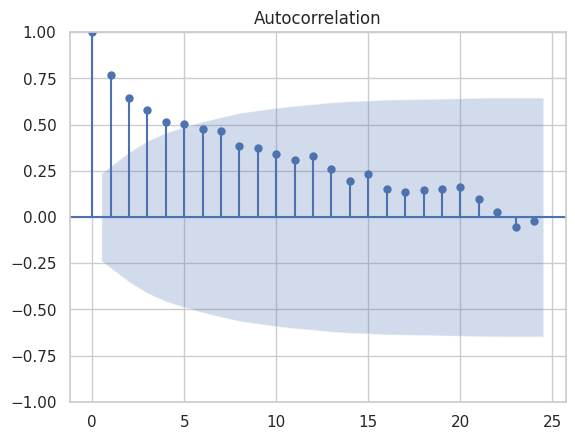

In [8]:
p_level = adfuller(ts)[1]
p_diff = adfuller(ts.diff().dropna())[1]
print(f"ADF test p-value, original series : {p_level:.3f}  (below 0.05 = stationary; the first value is borderline)")
print(f"ADF test p-value, first difference: {p_diff:.3f}")
plot_acf(ts, lags=24); plt.show()

### Interpretation: autocorrelation

The first bar (lag 0) is always 1, since a series matches itself perfectly. Each following bar shows how strongly a month relates to the month that many steps earlier. Bars that rise above the shaded band are statistically meaningful.

**Short-term memory:** The correlation is strong at lag 1 (about 0.77) and fades slowly, staying above the band for roughly the first four or five lags. In practice, a month with many additions is usually followed by another busy month.

**Slow fade:** This gradual decline is typical of a series with a trend, which fits the growth from 2016 to 2019.

**Yearly pattern:** At lag 12 the bar is only about 0.33, well inside the band, and there is no clear bump. So the same month a year earlier is not a strong predictor, which matches the moderate seasonality (0.35) found earlier.

## 3. Build forecasting models
Eight models, from simple to advanced, so that complex models have to **earn** their place against simple baselines:

| Family | Model | Idea |
|---|---|---|
| Baselines | Naive | next months = last value |
| | Seasonal naive | next months = same month last year |
| | Mean of last 6 months | average of recent values |
| Statistical | Holt (damped trend) | smoothed level + damped trend |
| | Holt-Winters | adds a yearly seasonal pattern |
| | SARIMA(1,1,1)(0,1,1,12) | autoregressive model with seasonality |
| Machine learning | Random Forest | learns from lags, rolling means, calendar |
| | Gradient Boosting | same features, boosted trees |

The machine learning models forecast **recursively**: each predicted month is fed back as a lag for the next one.

In [9]:
def f_naive(train, h):   return np.repeat(train.iloc[-1], h)
def f_snaive(train, h):  last = train.values[-12:]; return np.array([last[i % 12] for i in range(h)])
def f_mean6(train, h):   return np.repeat(train.iloc[-6:].mean(), h)

def f_holt(train, h):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return ExponentialSmoothing(train, trend="add", damped_trend=True).fit().forecast(h).values

def f_hw(train, h):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        m = ExponentialSmoothing(train, trend="add", damped_trend=True, seasonal="add", seasonal_periods=12)
        return m.fit().forecast(h).values

def f_sarima(train, h):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        m = SARIMAX(train, order=(1, 1, 1), seasonal_order=(0, 1, 1, 12),
                    enforce_stationarity=False, enforce_invertibility=False)
        return m.fit(disp=False).forecast(h).values

def row_features(hist, date, t):
    h = np.asarray(hist)
    return [t, np.sin(2 * np.pi * date.month / 12), np.cos(2 * np.pi * date.month / 12),
            h[-1], h[-2], h[-3], h[-12], h[-3:].mean(), h[-6:].mean()]

def ml_forecast(train, h, make_model):
    vals, idx = train.values, train.index
    X = [row_features(vals[:i], idx[i], i) for i in range(12, len(vals))]
    y = vals[12:]
    model = make_model().fit(X, y)
    hist, preds = list(vals), []
    for k in range(h):
        date = idx[-1] + pd.DateOffset(months=k + 1)
        p = model.predict([row_features(hist, date, len(hist))])[0]
        preds.append(p); hist.append(p)
    return np.array(preds)

def f_rf(train, h): return ml_forecast(train, h, lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=RS))
def f_gb(train, h): return ml_forecast(train, h, lambda: GradientBoostingRegressor(n_estimators=150, max_depth=2, learning_rate=0.05, random_state=RS))

models = {
    "Naive": f_naive, "Seasonal naive": f_snaive, "Mean of last 6 months": f_mean6,
    "Holt (damped trend)": f_holt, "Holt-Winters": f_hw, "SARIMA": f_sarima,
    "Random Forest": f_rf, "Gradient Boosting": f_gb,
}
print(list(models))

['Naive', 'Seasonal naive', 'Mean of last 6 months', 'Holt (damped trend)', 'Holt-Winters', 'SARIMA', 'Random Forest', 'Gradient Boosting']


## 4. Evaluation setup
Time series must never be split randomly. We evaluate in two ways, always training on the past and testing on the future:

1. **12-month holdout**: train on Jan 2016 to Aug 2020, test on the last 12 months (Sep 2020 to Aug 2021).

2. **Rolling-origin backtest**: repeatedly train on all data up to a month, forecast the next 3 months, then move forward by 2 months. It uses 16 different starting points, so it is much more reliable than a single holdout of 12 noisy points.

Metrics: **MAE** (average error in titles), **RMSE** (penalizes large errors), **MAPE** (average % error) and **MASE** (error divided by the average error of guessing "same as last month" on the training data; a value near 1 means the forecast is about as accurate as that simple guess, even though it looks several months ahead).

In [10]:
def metrics(actual, pred, scale):
    actual, pred = np.asarray(actual, float), np.asarray(pred, float)
    err = actual - pred
    return {"MAE": np.mean(np.abs(err)),
            "RMSE": np.sqrt(np.mean(err ** 2)),
            "MAPE %": np.mean(np.abs(err) / actual) * 100,
            "MASE": np.mean(np.abs(err)) / scale}

H = 12
train, test = ts.iloc[:-H], ts.iloc[-H:]
naive_scale = np.mean(np.abs(np.diff(train.values)))   # in-sample one-step naive error

holdout_preds, rows = {}, []
for name, fn in models.items():
    pred = np.clip(fn(train, H), 0, None)
    holdout_preds[name] = pred
    rows.append({"model": name, **metrics(test.values, pred, naive_scale)})
holdout = pd.DataFrame(rows).set_index("model").round(2).sort_values("MAE")
print("Train:", train.index[0].date(), "to", trainTrain: 2016-01-01 to 2020-08-01 | Test: 2020-09-01 to 2021-08-01

	MAE 	RMSE 	MAPE % 	MASE
model 				
Holt (damped trend) 	31.83 	41.29 	22.09 	1.21
Mean of last 6 months 	33.47 	42.40 	19.86 	1.27
Random Forest 	34.41 	43.48 	20.52 	1.31
Holt-Winters 	40.06 	47.83 	26.92 	1.52
Naive 	41.58 	53.42 	22.53 	1.58
Gradient Boosting 	42.94 	50.03 	25.65 	1.63
SARIMA 	46.66 	57.01 	27.24 	1.77
Seasonal naive 	47.33 	57.06 	28.13 	1.80.index[-1].date(), "| Test:", test.index[0].date(), "to", test.index[-1].date())
holdout

Train: 2016-01-01 to 2020-08-01 | Test: 2020-09-01 to 2021-08-01


,MAE,RMSE,MAPE %,MASE
model,,,,
Holt (damped trend),31.83,41.29,22.09,1.21
Mean of last 6 months,33.47,42.40,19.86,1.27
Random Forest,34.41,43.48,20.52,1.31
Holt-Winters,40.06,47.83,26.92,1.52
Naive,41.58,53.42,22.53,1.58
Gradient Boosting,42.94,50.03,25.65,1.63
SARIMA,46.66,57.01,27.24,1.77
Seasonal naive,47.33,57.06,28.13,1.80


### Interpretation: 12-month holdout results

Holt's method with a damped trend had the lowest error (MAE 31.8), meaning its forecasts were off by about 32 titles a month on average. The average of the last 6 months (33.5) and the Random Forest (34.4) were close behind, and the gap between these three is small. The average of the last 6 months even had the best percentage error (MAPE 19.9%). With months averaging around 160 titles, all three are typically off by about 20%.

The seasonal models did worst: seasonal naive (47.3) and SARIMA (46.7) had the largest errors, and Holt-Winters (40.1) did clearly worse than plain Holt (31.8). So adding a yearly pattern hurt rather than helped, which fits the weak seasonality found earlier. Simply repeating last month's value (Naive, 41.6) also lost to the best models.

MASE is above 1 for every model. This is expected, because it is measured against a one-month-ahead guess while these forecasts look 12 months ahead, so it should be read as a way to compare models rather than as a failure.

This is only one 12-month test, and 2020 and 2021 were unusual, so the ranking is a hint, not proof. The rolling backtest gives a second opinion.

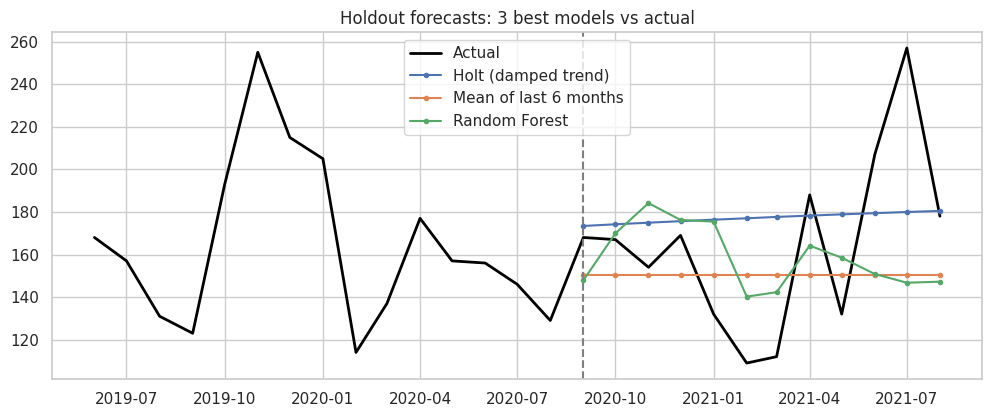

In [11]:
fig, ax = plt.subplots(figsize=(12, 4.5))
hist = ts.loc["2019-06-01":]
ax.plot(hist.index, hist.values, color="black", lw=2, label="Actual")
top = holdout.index[:3]
for name in top:
    ax.plot(test.index, holdout_preds[name], marker="o", ms=3, label=name)
ax.axvline(test.index[0], color="gray", ls="--")
ax.set_title("Holdout forecasts: 3 best models vs actual"); ax.legend(); plt.show()

### Interpretation: holdout forecasts

The black line is what actually happened, and the three colored lines are the best models' forecasts for the same 12 months (September 2020 to August 2021).

**Holt (damped trend)** is almost a flat line slightly above 170. It sits close to the average level of the year but ignores the ups and downs. It overestimates the quiet months at the start of 2021 and falls short of the summer peak.

**Mean of last 6 months** is a flat line at about 150. It is too low for most of the period, which still earns it a good percentage error because it is close to the real average in the weaker months.

**Random Forest** is the only model that moves. It correctly predicts a dip in early 2021 and a rise around October 2020, but it misses the sharp jump in June and July 2021, when titles added reached about 207 and 257.

**Overall:** actual additions swing widely from month to month (109 to 257), and none of the models anticipated the spikes or the deepest drops. They mostly capture the average level, which is why their errors are all similar. This is a typical result for a short, noisy series.

In [12]:
HORIZON, STEP, MIN_TRAIN = 3, 2, 36
origins = list(range(MIN_TRAIN, len(ts) - HORIZON + 1, STEP))
print("Number of backtest origins:", len(origins))

bt_err = {name: [] for name in models}       # signed errors (actual - forecast)
for o in origins:
    tr, actual = ts.iloc[:o], ts.iloc[o:o + HORIZON].values
    for name, fn in models.items():
        pred = np.clip(fn(tr, HORIZON), 0, None)
        bt_err[name].append(actual - pred)

scale_all = np.mean(np.abs(np.diff(ts.values)))
rows = []
for name, errs in bt_err.items():
    e = np.concatenate(errs)
    rows.append({"model": name, "MAE": np.mean(np.abs(e)), "RMSE": np.sqrt(np.mean(e ** 2)),
                 "MASE": np.mean(np.abs(e)) / scale_all})
backtest = pd.DataFrame(rows).set_index("model").round(2).sort_values("MAE")
backtest

Number of backtest origins: 15


,MAE,RMSE,MASE
model,,,
Random Forest,29.90,40.65,1.05
Mean of last 6 months,30.59,40.26,1.07
Naive,34.22,43.46,1.20
Gradient Boosting,34.51,45.06,1.21
Holt (damped trend),34.71,41.71,1.22
Holt-Winters,34.99,45.64,1.23
Seasonal naive,37.16,48.58,1.30
SARIMA,37.86,48.51,1.33


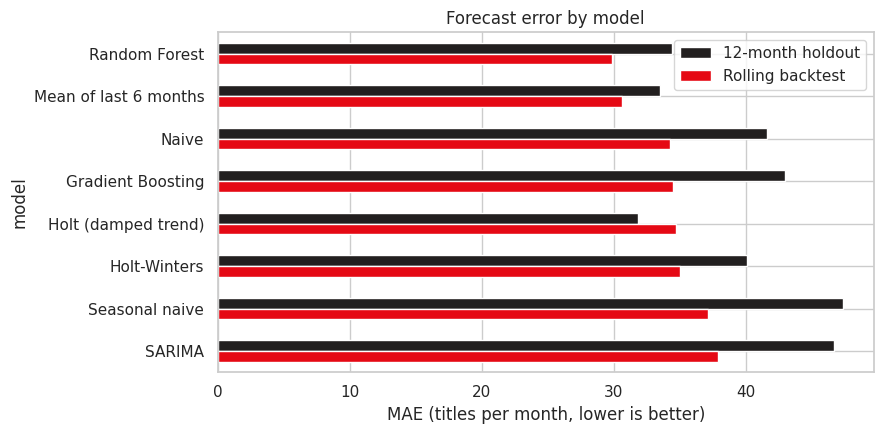

In [13]:
comp = pd.DataFrame({"12-month holdout": holdout["MAE"], "Rolling backtest": backtest["MAE"]}).loc[backtest.index]
comp.plot.barh(figsize=(9, 4.5), color=["#221f1f", "#e50914"]).invert_yaxis()
plt.xlabel("MAE (titles per month, lower is better)"); plt.title("Forecast error by model"); plt.tight_layout(); plt.show()


### Interpretation: forecast error by model

Each model has two bars: the black one is the 12-month holdout and the red one is the rolling backtest. Shorter is better.

**The ranking depends on the test.** The Random Forest has the lowest error in the backtest (about 30 titles a month), but only third on the holdout. Holt with damped trend is the opposite: best on the holdout (about 32) and fifth in the backtest (about 35). Because the winner changes, neither result alone is enough to name a single best model.

**Some results are consistent.** The average of the last 6 months stays near the top in both tests (about 31 to 33), and Seasonal naive and SARIMA are among the worst in both (about 37 to 47). Models built around a yearly pattern did not help on this series.

**Holdout errors are mostly larger.** That is expected, since the holdout forecasts 12 months ahead while the backtest looks only 3 months ahead, and the holdout period (2020 and 2021) was unusual.

**Overall:** the differences between the top models are small (a few titles a month), so a simple average is almost as good as the more complex models.


## 5. Generate future predictions
The best model according to the **rolling backtest** (the more reliable of the two evaluations) is refit on **all** available data and used to forecast the next 12 months. Because no model can give a perfect prediction, we add an **80% prediction interval** built from the model's own backtest errors.

In [14]:
best = backtest["MAE"].idxmin()
print("Best model (rolling backtest MAE):", best)

future_idx = pd.date_range(ts.index[-1] + pd.DateOffset(months=1), periods=12, freq="MS")
point = np.clip(models[best](ts, 12), 0, None)

errs = np.concatenate(bt_err[best])
lo_q, hi_q = np.percentile(errs, [10, 90])
forecast = pd.DataFrame({"forecast": point, "lower 80%": np.clip(point + lo_q, 0, None), "upper 80%": point + hi_q},
                        index=future_idx).round(0).astype(int)
forecast.index = forecast.index.strftime("%Y-%m")
forecast

Best model (rolling backtest MAE): Random Forest


,forecast,lower 80%,upper 80%
2021-09,150,108,201
2021-10,150,109,201
2021-11,160,118,211
2021-12,159,118,211
2022-01,150,109,201
2022-02,144,103,195
2022-03,141,99,192
2022-04,167,125,218
2022-05,152,111,203
2022-06,160,119,211



### Interpretation: 12-month forecast

The Random Forest, which had the lowest error in the backtest, predicts between 141 titles (March 2022) and 167 (April 2022) per month. That adds up to about 1,844 titles for the year, or 154 a month, roughly 6.5% fewer than the previous 12 months.

**The forecast is nearly flat.** The gap between the lowest and highest month is only 26 titles, while the 80% interval around each month is about 90 titles wide (for example, 108 to 201 for September 2021). In other words, the real number could easily land anywhere in that range, so the small differences between months mean very little.

**It starts below the most recent data.** The last months in the dataset were unusually high (207, 257 and 178), but the model predicts around 150 for September. It expects the pace to settle back toward the long-term average rather than keep climbing.

**The interval has the same width every month.** It is built from the model's past errors, so it does not widen the further ahead we look, and it is probably a little optimistic for the later months.

**The monthly pattern is weak.** The lowest forecast is March, even though March was usually a busy month in the history. This is another sign that the model captures the average level better than the yearly rhythm.

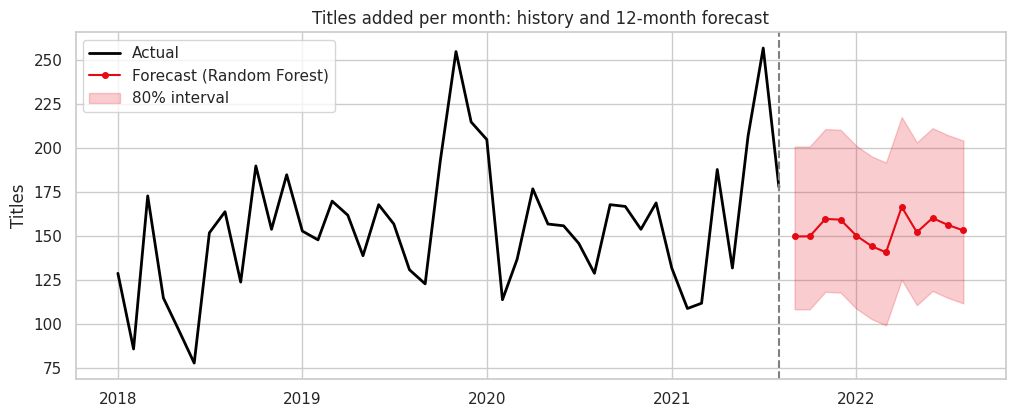

In [15]:
fig, ax = plt.subplots(figsize=(12, 4.5))
hist = ts.loc["2018-01-01":]
ax.plot(hist.index, hist.values, color="black", lw=2, label="Actual")
ax.plot(future_idx, point, color="#e50914", marker="o", ms=4, label=f"Forecast ({best})")
ax.fill_between(future_idx, np.clip(point + lo_q, 0, None), point + hi_q, color="#e50914", alpha=.2, label="80% interval")
ax.axvline(ts.index[-1], color="gray", ls="--")
ax.set_title("Titles added per month: history and 12-month forecast"); ax.set_ylabel("Titles"); ax.legend(); plt.show()

### Interpretation: history and 12-month forecast

The black line is what really happened. The dashed line marks where the data ends (August 2021), and the red line with the shaded band is the forecast for September 2021 to August 2022.

The first thing you notice is how calm the forecast looks next to the history. Real monthly additions bounced between about 110 and 257 titles, while the forecast stays between roughly 140 and 167. The model is guessing the typical month, not the spikes and dips.

It also starts well below where the data ends. The last few months climbed sharply (about 207, then 257, then 178), yet the forecast picks up at around 150. The model expects things to cool off and drift back toward the long-term average instead of continuing upward.

The shaded band is wide, from about 100 to 215 titles. It would have covered almost every month of 2020 and 2021, so the forecast is reasonable for a normal month. The biggest spikes, like the 255 and 257, would still land above it.


In [16]:
last12 = ts.iloc[-12:]
print(f"Last 12 months (actual)    : {last12.sum():.0f} titles, average {last12.mean():.0f} per month")
print(f"Next 12 months (forecast)  : {point.sum():.0f} titles, average {point.mean():.0f} per month")
print(f"Change                     : {(point.sum() / last12.sum() - 1) * 100:+.1f}%")
print(f"Busiest forecast month     : {future_idx[point.argmax()].strftime('%B %Y')} ({point.max():.0f} titles)")
print(f"Quietest forecast month    : {future_idx[point.argmin()].strftime('%B %Y')} ({point.min():.0f} titles)")

Last 12 months (actual)    : 1973 titles, average 164 per month
Next 12 months (forecast)  : 1844 titles, average 154 per month
Change                     : -6.5%
Busiest forecast month     : April 2022 (167 titles)
Quietest forecast month    : March 2022 (141 titles)


## Conclusion

Netflix grew its catalogue quickly between 2016 and 2019, then settled at around 160 new titles a month. There is a mild yearly rhythm: December, October and March tend to be busy, while February, May and June are quieter.

The data is short and noisy, so fancy models did not have much room to shine. The Random Forest came out best in the backtest (about 30 titles of error per month), but it only edged out simply averaging the last six months. On the final 12-month test, Holt's method won instead. Because the winner changes with the evaluation method, I report both.

Looking ahead, the model expects about 1,840 titles over the next 12 months (roughly 154 a month), around 6% fewer than the last year. Each monthly forecast can be off by 40 to 50 titles either way, so I would not read too much into which month looks busiest.

**Perspectives:** forecast Movies and TV Shows separately, and add outside information such as planned releases or holidays.